# Bayesian Parameter Estimation for Dynamical Models in Systems Biology: the MAPK Cascade

__Nathaniel J. Linden__, Department of Mechanical and Aerospace Engineering, University of California San Diego, San Diego, California, United States of America

__Boris Kramer__, Department of Mechanical and Aerospace Engineering, University of California San Diego, San Diego, California, United States of America

__Padmini Rangamani__, Department of Mechanical and Aerospace Engineering, University of California San Diego, San Diego, California, United States of America

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

This notebook studies the simplified MAPK (RAF/MEK/ERK) cascade of [[1]][R1], Sec. 2.2, in its two dynamical regimes, bistable steady states and limit-cycle oscillations, with the seven parameters that the paper varies in its Sobol' study. It runs in Python 3 with numpy, scipy and matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later. The data are in this directory (`generate_data.py` writes them from `MAPK_model.py`; see `DATA.md`).

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import MAPK_model as mm

SEED = 570                        # the only seed in this notebook (every rng=)
t_start = time.perf_counter()
labels = [r'$k_1$', r'$k_2$', r'$k_3$', r'$k_4$', r'$k_5$', r'$k_6$', r'$\alpha$']
NAMES = list(mm.NAMES)

### Summary

Linden, Kramer and Rangamani [[1]][R1] calibrate a three-state model of the MAPK cascade with Bayesian methods and, before that, rank its seven free rate parameters with Sobol' indices in a bistable and an oscillatory regime. We reimplement the model in Python with forward-sensitivity gradients and estimate active subspaces on 512-point Sobol' designs; in our headline design (Study 3) each parameter is log-uniform on $[U/100, U]$, with $U$ the paper's upper bound, so every sample lies inside the paper's box, and there $x_3$ at 30 min has a one-dimensional active subspace that weighs the activation rates $k_1, k_3, k_5, \alpha$ against the deactivation rates $k_2, k_4, k_6$ ($\lambda_1/\lambda_2 \approx 12$: 12.8 without row 306, 10.5 without the 5 largest gradients, 12.0 on rows 0–255, with $\mathbf w_1$ stable, $|\mathbf w_1^T\mathbf w_1'| \ge 0.955$; with all samples the ratio is 74.4 only because one sample near the separatrix carries 84 % of the trace; $\mathrm{corr}(y_1, f) = 0.88$; cubic surrogate in $y_1$ LOO $R^2 = 0.87$). On the paper's own linear designs, whose ranges start at 0, a few samples with a deactivation rate near 0 set the gradient matrix (the 5 largest gradients carry 90 % and 66 % of its trace, and without them $\lambda_1/\lambda_2$ falls from 10.4 to 1.6 and from 2.2 to 1.2), while the limit-cycle amplitude, analysed on the 171 oscillating samples only, has $\lambda_1/\lambda_2 = 5.7$ led by $k_2$ (activity score 0.51), as in the paper's Fig. 4D.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and is nearly constant along $\mathbf W_2^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a surrogate in $\mathbf y$ can replace $f$. We estimate $\mathbf C$ by the sample average of gradient outer products and assess it with the bootstrap; where gradients are not meaningful we estimate them from local linear fits to the values. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

### The model

The model ([[1]][R1], Eqs. 32a–c, p. 28, from Nguyen et al. [[2]][R2]) has three states, the phosphorylated RAF, MEK and MAPK/ERK concentrations $x_1, x_2, x_3$ (nM):

$$
\begin{aligned}
\dot x_1 &= k_1 (S_{1t} - x_1)\,\frac{K_1^{n_1}}{K_1^{n_1} + x_3^{n_1}} - k_2 x_1,\\
\dot x_2 &= k_3 (S_{2t} - x_2)\, x_1 \left(1 + \frac{\alpha\, x_3^{n_2}}{K_2^{n_2} + x_3^{n_2}}\right) - k_4 x_2,\\
\dot x_3 &= k_5 (S_{3t} - x_3)\, x_2 - k_6 x_3,
\end{aligned}
$$

with 14 parameters: $k_1, k_3, k_5$ activate, $k_2, k_4, k_6$ deactivate, ERK inhibits RAF activation (negative feedback, $K_1, n_1$) and promotes MEK activation (positive feedback, $\alpha, K_2, n_2$). Two nominal parameter sets give the two regimes (S2 Table of [[1]][R1]; the values here are from the authors' code, since the S2 Table file was not opened). Time is in seconds, as in the authors' code ($t = 1800$ s is the paper's 30 min); concentrations are in nM (the paper's Fig. 4B axes).

**Which parameters vary.** The paper's text (p. 28) says the free set was narrowed "down to a set of 9 parameters, from a set of 14", after fixing $n_1, n_2$ (exponents), $K_1, K_2$ (only locally identifiable) and $S_{1t}, S_{2t}, S_{3t}$ (cell-type totals). That fixes 7 of 14 and leaves 7, the list in the Fig. 4 caption and in the authors' script (`fixedParamIndex = [1,2,3,10,11,12,13]`, so the free parameters are $k_1,\dots,k_6,\alpha$). We take $m = 7$; the "9" in the text does not match its own list.

**Three studies**, each a scrambled Sobol' design of $M = 512$ points:

1. *Paper's bistable design*: $k_1,\dots,k_6,\alpha$ independent uniform on the ranges of the authors' code (`paramBounds` in `MAPK/sensitivity_analysis_RUN.m`; the paper refers to its S2 Table), the rest at the bistable nominal values.
2. *Paper's oscillatory design*: the same ranges with $k_5 \ge 10^{-5}$ (S2 Table note), the rest at the oscillatory nominal values.
3. *Log-uniform design inside the paper's box* (ours; the headline): $\ln\theta_i$ uniform on $[\ln(U_i/100), \ln U_i]$, with $U_i$ the upper bound of the paper's range (`paramBounds`). Every sample lies inside the paper's box, and so does the bistable nominal point ($k_1^* = 0.0012 \ge U_1/100 = 0.001$). Log-uniform inputs are the convention the paper uses for its third model (S4 Table caption). We add this design because the paper's ranges start at 0, where the derivatives with respect to a deactivation rate become very large (Study 1, below); a log scale removes that lower bound. An earlier version of this notebook used $[\theta_i^*/10,\, 10\,\theta_i^*]$ around the nominal values instead. Its upper ends were 6.6 to 9.8 times the paper's for $k_3, k_4, k_5, k_6, \alpha$ ($\alpha$ up to 950 against 100), so most of its samples had some parameter in a region the paper never sampled. We dropped it (`DATA.md` gives the numbers and the reasons).

**Quantities of interest.**

* *Bistable regime* (the paper's QoIs): $x_3$ and $x_2$ at $t = 1800$ s from the paper's high-steady-state initial condition $\mathbf x_0 = (0.1245, 2.4870, 31.2623)$ and its low-steady-state one $(0.0015, 3.6678, 28.7307)$ (Fig. 4 caption). A state at a fixed finite time is a smooth function of the parameters, so gradients exist everywhere, but they are large where a trajectory passes close to the separatrix between the two basins of attraction. Our main QoI is $f_B = x_3(1800\,\mathrm{s})$ from the high-state initial condition.
* *Oscillatory regime*: the paper's QoIs, the limit-cycle amplitude and period of $x_3$ ([[1]][R1], Sec. 1.13, Eqs. 29–30), are set to 0 when no limit cycle is detected (the authors' `nullValue`), so they jump at the edge of the oscillating region and depend on peak detection on a 20 s grid inside it. They are not differentiable. We estimate gradients of the amplitude and the period from values by local linear fits, first on the oscillating samples only (the headline for Study 2), then on all samples with the 0s, which is the like-for-like comparison with the paper's Sobol' indices. A smooth QoI that is not in the paper is $f_O = \overline{x_3}$, the mean of $x_3$ on the 20 s grid over $980 \le t \le 5400$ s (the window the authors use for the limit-cycle features; their script computes this mean as a third QoI, `meanQOI`, not shown in the paper), from $\mathbf x_0 = (10, 80, 80)$. It is smooth, but in oscillating samples it depends on how many periods fit in the window, so it is wiggly along the parameters that set the period; it is a negative result, shown last.

**Gradients.** Forward sensitivities: the 21 equations $\dot{\mathbf s}_j = \mathbf J\mathbf s_j + \partial\mathbf f/\partial\theta_j$ are solved with the states (LSODA, $\mathrm{rtol} = \mathrm{atol} = 10^{-10}$ bistable, $10^{-8}$ oscillatory), so the derivatives are exact up to the solver tolerance.

The input table below is printed from `MAPK_model.py` and `generate_data.py`.

In [2]:
import generate_data as gd
units = ['1/s', '1/s', '1/(nM s)', '1/s', '1/(nM s)', '1/s', '1']
print(f"{'input':6s} {'units':9s} {'nominal (B)':>11s} {'Study 1 range':>16s} {'Study 3 range (log-unif.)':>26s} {'nominal (O)':>11s} {'Study 2 range':>16s}")
for j, n in enumerate(NAMES):
    print(f'{n:6s} {units[j]:9s} {mm.NOMINAL_BISTABLE[mm.FREE][j]:11g} ' +
          f'[{mm.LOWER_BISTABLE[j]:g}, {mm.UPPER_BISTABLE[j]:g}]'.rjust(16) +
          f'[{gd.LOWER_LOG[j]:.4g}, {gd.UPPER_LOG[j]:.4g}]'.rjust(26) + f' {mm.NOMINAL_OSCILLATORY[mm.FREE][j]:11g} ' +
          f'[{mm.LOWER_OSCILLATORY[j]:g}, {mm.UPPER_OSCILLATORY[j]:g}]'.rjust(16))
inside = np.all(gd.LOWER_LOG >= mm.LOWER_BISTABLE) and np.all(gd.UPPER_LOG <= mm.UPPER_BISTABLE)
nf = mm.NOMINAL_BISTABLE[mm.FREE]
print(f'Study 3 box inside the Study 1 (paper) box: {inside}; contains the bistable nominal point: '
      f'{np.all((nf >= gd.LOWER_LOG) & (nf <= gd.UPPER_LOG))}')
held = [i for i in range(14) if i not in mm.FREE]
print('held, bistable (B):   ', ', '.join(f'{mm.ALL_NAMES[i]} = {mm.NOMINAL_BISTABLE[i]:g}' for i in held))
print('held, oscillatory (O):', ', '.join(f'{mm.ALL_NAMES[i]} = {mm.NOMINAL_OSCILLATORY[i]:g}' for i in held))
qh, _ = mm.bistable(nf, mm.X0_HIGH, gradients=False)
ql, _ = mm.bistable(nf, mm.X0_LOW, gradients=False)
o = mm.oscillatory(mm.NOMINAL_OSCILLATORY[mm.FREE], gradients=False)
print(f'nominal bistable: x3(1800 s) = {qh[1]:.4f} nM (high-state x0), {ql[1]:.4f} nM (low-state x0)')
print(f"nominal oscillatory (data QoIs, window 980-5400 s): mean x3 = {o['mean_x3']:.4f} nM, "
      f"amplitude = {o['amplitude']:.4f} nM, period = {o['period']:.4f} min")

input  units     nominal (B)    Study 1 range  Study 3 range (log-unif.) nominal (O)    Study 2 range
k1     1/s            0.0012         [0, 0.1]              [0.001, 0.1]         0.1         [0, 0.1]
k2     1/s             0.006         [0, 0.1]              [0.001, 0.1]        0.01         [0, 0.1]
k3     1/(nM s)        0.049        [0, 0.05]            [0.0005, 0.05]        0.01        [0, 0.05]
k4     1/s             0.084         [0, 0.1]              [0.001, 0.1]        0.01         [0, 0.1]
k5     1/(nM s)        0.043        [0, 0.05]            [0.0005, 0.05]        0.01    [1e-05, 0.05]
k6     1/s             0.066         [0, 0.1]              [0.001, 0.1]        0.01         [0, 0.1]
alpha  1                  95         [0, 100]                  [1, 100]          10         [0, 100]
Study 3 box inside the Study 1 (paper) box: True; contains the bistable nominal point: True
held, bistable (B):    S1t = 0.22, S2t = 10, S3t = 53, n1 = 5, K1 = 9.5, n2 = 10, K2 = 15
held, osc

nominal bistable: x3(1800 s) = 17.9175 nM (high-state x0), 5.9889 nM (low-state x0)
nominal oscillatory (data QoIs, window 980-5400 s): mean x3 = 18.2492 nM, amplitude = 26.9620 nM, period = 13.0417 min


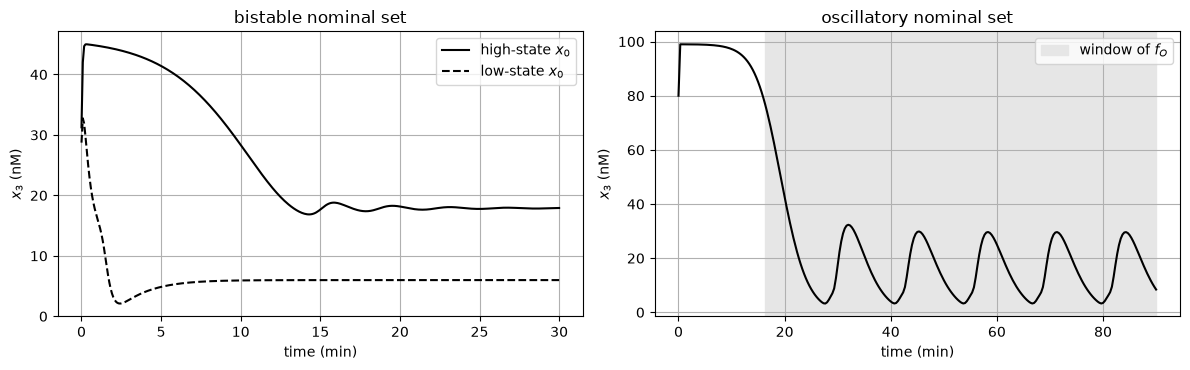

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
tb = np.linspace(0, 1800, 361)
for x0, ls, lab in [(mm.X0_HIGH, '-', 'high-state $x_0$'), (mm.X0_LOW, '--', 'low-state $x_0$')]:
    y, _ = mm.solve(mm.NOMINAL_BISTABLE, x0, tb, False)
    axes[0].plot(tb / 60, y[2], 'k' + ls, label=lab)
axes[0].set_title('bistable nominal set')
to = mm.osc_times()
y, _ = mm.solve(mm.NOMINAL_OSCILLATORY, mm.X0_OSC, to, False)
axes[1].plot(to / 60, y[2], 'k')
axes[1].axvspan(to[mm.START_OSC] / 60, to[-1] / 60, color='0.9', label='window of $f_O$')
axes[1].set_title('oscillatory nominal set')
for ax in axes:
    ax.set_xlabel('time (min)')
    ax.set_ylabel('$x_3$ (nM)')
    ax.legend()
    ax.grid(True)
fig.tight_layout()
plt.close(fig)
fig

In [4]:
# Nominal limit-cycle amplitude two ways: the data's window (from 980 s, MATLAB startIdx = 50) and the
# settled cycle (run to 20000 s, cycles after 10000 s), each read with the true minima and with the
# one-sample-late minima of the authors' limitCycleFeatures.m (lMin = trajectory(delay+minLocs))
from scipy.signal import find_peaks
for label, t_end, t0 in [('data window 980-5400 s', 5400.0, 980.0), ('settled cycle 10000-20000 s', 20000.0, 10000.0)]:
    t = np.arange(0.0, t_end + mm.DT_OSC / 2, mm.DT_OSC)
    y, _ = mm.solve(mm.NOMINAL_OSCILLATORY, mm.X0_OSC, t, False, 1e-10, 1e-10)
    w = t >= t0 - mm.DT_OSC / 2
    x3 = y[2, w]
    a_true, per = mm.limit_cycle_features(x3, mm.DT_OSC)
    a_late, _ = mm.limit_cycle_features(x3, mm.DT_OSC, late_minima=True)
    print(f'{label}: amplitude {a_true:.2f} nM (true minima), {a_late:.2f} nM (late minima, authors\' code); period {per:.2f} min')
    imax, _ = find_peaks(x3)
    imin, _ = find_peaks(-x3)
    k = min(len(imax), len(imin))
    print(f'   {k} cycles; amplitudes (true minima) ' + ', '.join(f'{v:.2f}' for v in (x3[imax] [:k] - x3[imin][:k])[:6]) +
          ('' if k <= 6 else ', ...') + f'; first maximum at t = {t[w][imax[0]] / 60:.0f} min')
    if t0 < 1000:
        print(f'   mean amplitude without the first cycle {np.mean(x3[imax[1:k]] - x3[imin[1:k]]):.2f} nM')

data window 980-5400 s: amplitude 26.96 nM (true minima), 26.72 nM (late minima, authors' code); period 13.04 min
   5 cycles; amplitudes (true minima) 29.09, 26.60, 26.39, 26.37, 26.36; first maximum at t = 32 min
   mean amplitude without the first cycle 26.43 nM


settled cycle 10000-20000 s: amplitude 26.33 nM (true minima), 26.06 nM (late minima, authors' code); period 12.99 min
   13 cycles; amplitudes (true minima) 26.32, 26.32, 26.32, 26.33, 26.32, 26.32, ...; first maximum at t = 175 min


At the bistable nominal values the two initial conditions end 30 min later at $x_3 = 17.92$ nM and $5.99$ nM, the high and low steady states of the paper's Fig. 4B (about 18 and 6 nM there).

At the oscillatory nominal values the period on the data's window is 13.04 min, as in the paper (13.04, p. 30). The amplitude depends on the window and on how the minima are read:

* *The data's QoI* follows the authors' sensitivity script: the window runs from 980 s (MATLAB `startIdx = 50`) to 5400 s, the minima are the true local minima, and the amplitude is 26.96 nM. This window still contains a transient first cycle. Its maximum is at 32 min and its amplitude is 29.09 nM, against 26.60 to 26.36 nM for the next four cycles. It passes the code's decay test ($29.09 - 26.36 = 2.73 < 5$ nM). Without it the mean is 26.43 nM. We keep the authors' GSA definition for the data.
* *The settled cycle* (run to 20000 s, cycles after 10000 s) has amplitude 26.33 nM with the true minima. With the one-sample-late minima of the authors' `limitCycleFeatures.m` (`lMin = trajectory(delay+minLocs)` with 1-based locations, so one grid point late) it is **26.06 nM**, 0.06 nM below the paper's 26.12. We take 26.06 as the nominal value to compare with the paper. The paper's "true" amplitude most likely belongs to the settled cycle, read the authors' way, but this is not proven. On this window the period is 12.99 min, so the paper's 13.04 matches the data window.

An earlier version of this notebook compared 26.96 with 26.12. The gap of 0.90 nM from 26.96 to 26.06 is made of the transient first cycle ($26.96 - 26.43 = 0.53$), the slower settling of the next cycles ($26.43 - 26.33 = 0.10$) and the late minima ($26.33 - 26.06 = 0.27$). It is not a difference in the model.

### Load data

`generate_data.py` drew three scrambled Sobol' designs of $M = 512$ points (seeds 570, 571 and 572) and wrote the physical inputs, the outputs, and the forward-sensitivity gradients with respect to the physical inputs (see `DATA.md`).

In [5]:
D = {}
for st in ['bistable', 'oscillatory', 'bistable_log']:
    D[st] = [np.loadtxt(f'{st}_{kind}.csv', delimiter=',') for kind in ['inputs', 'outputs', 'gradients']]
    print(f'{st:13s} inputs {D[st][0].shape}, outputs {D[st][1].shape}, gradients {D[st][2].shape}')
Xb, Fb, Gb = D['bistable'];     Gb = Gb.reshape(-1, 4, 7)   # outputs: x2_high, x3_high, x2_low, x3_low
Xo, Fo, Go = D['oscillatory']                               # outputs: mean_x3, amplitude, period, oscillates
Xl, Fl, Gl = D['bistable_log']; Gl = Gl.reshape(-1, 4, 7)

bistable      inputs (512, 7), outputs (512, 4), gradients (512, 28)
oscillatory   inputs (512, 7), outputs (512, 4), gradients (512, 7)
bistable_log  inputs (512, 7), outputs (512, 4), gradients (512, 28)


Study 3 is analyzed in log coordinates. This is the one cell that converts: $\mathbf Z = \ln\mathbf X$ and $\partial f/\partial z_i = \theta_i\,\partial f/\partial \theta_i$. Every input of every study is then uniform in its analysis coordinates and is normalized by its own half-range.

In [6]:
Zl = np.log(Xl)
Gzl = Gl * Xl[:, None, :]
space_b = ac.Uniform(mm.LOWER_BISTABLE, mm.UPPER_BISTABLE, names=NAMES)
space_o = ac.Uniform(mm.LOWER_OSCILLATORY, mm.UPPER_OSCILLATORY, names=NAMES)
space_l = ac.Uniform(np.log(gd.LOWER_LOG), np.log(gd.UPPER_LOG), names=[f'ln {n}' for n in NAMES])

We check the stored outputs at four samples of each design against tight solves of the model without sensitivities ($\mathrm{rtol} = \mathrm{atol} = 10^{-12}$), and the stored gradients there against central differences of such solves (relative step $10^{-5}$). Central differences need care near the edge of the oscillating region: at oscillating sample 312 of Study 2 (amplitude 1.3 nM) a relative step of $10^{-5}$ gives a relative error of $5.4\times10^{-3}$, and $10^{-6}$ gives $4.6\times10^{-5}$ (`DATA.md`). The four rows used here are not such points. We also count samples outside the model's meaning, and samples whose two initial conditions end in different states (the model is bistable at that parameter point within 30 min).

In [7]:
tight = 1e-12
def fd(q, x, rel=1e-5):
    g = np.empty(7)
    for j in range(7):
        e = np.zeros(7); e[j] = rel * x[j]
        g[j] = (q(x + e) - q(x - e)) / (2 * rel * x[j])
    return g
for st, X, F, G in [('bistable', Xb, Fb[:, 1], Gb[:, 1]), ('bistable_log', Xl, Fl[:, 1], Gl[:, 1]), ('oscillatory', Xo, Fo[:, 0], Go)]:
    rows = [0, len(X) // 4, len(X) // 2, 3 * len(X) // 4]
    if st == 'oscillatory':
        q = lambda th: mm.solve(mm._full(th, mm.NOMINAL_OSCILLATORY), mm.X0_OSC, mm.osc_times(), False, tight, tight)[0][2, mm.START_OSC:].mean()
    else:
        q = lambda th: mm.solve(mm._full(th, mm.NOMINAL_BISTABLE), mm.X0_HIGH, [0, 1800.], False, tight, tight)[0][2, -1]
    ef = max(abs(q(X[i]) - F[i]) / abs(F[i]) for i in rows)
    eg = max(np.linalg.norm(fd(q, X[i]) - G[i]) / np.linalg.norm(fd(q, X[i])) for i in rows)
    print(f'{st:13s} tight solve vs file: max rel. diff {ef:.1e}; gradient vs central differences: max rel. error {eg:.1e}')
for st, F in [('bistable', Fb), ('oscillatory', Fo), ('bistable_log', Fl)]:
    print(f'{st:13s} negative or non-finite outputs: {np.sum(~np.isfinite(F) | (F < 0))}')
for st, F in [('bistable', Fb), ('bistable_log', Fl)]:
    bist = np.abs(F[:, 1] - F[:, 3]) > 1e-3 * np.maximum(F[:, 1], F[:, 3])
    print(f'{st:13s} {bist.sum()} of {len(F)} samples ({100 * bist.mean():.1f} %) end at different x3 from the two initial conditions')
osc = Fo[:, 3] == 1
print(f'oscillatory   {osc.sum()} of {len(Fo)} samples ({100 * osc.mean():.1f} %) show a limit cycle')

bistable      tight solve vs file: max rel. diff 6.0e-13; gradient vs central differences: max rel. error 2.7e-07


bistable_log  tight solve vs file: max rel. diff 7.4e-11; gradient vs central differences: max rel. error 1.1e-05


oscillatory   tight solve vs file: max rel. diff 7.7e-08; gradient vs central differences: max rel. error 1.0e-04
bistable      negative or non-finite outputs: 0
oscillatory   negative or non-finite outputs: 0
bistable_log  negative or non-finite outputs: 0
bistable      43 of 512 samples (8.4 %) end at different x3 from the two initial conditions
bistable_log  255 of 512 samples (49.8 %) end at different x3 from the two initial conditions
oscillatory   171 of 512 samples (33.4 %) show a limit cycle


The stored outputs agree with tight solves to $6.0\times10^{-13}$ (Study 1), $7.4\times10^{-11}$ (Study 3) and $7.7\times10^{-8}$ (Study 2, solved at $10^{-8}$). The stored gradients agree with central differences to $2.7\times10^{-7}$, $1.1\times10^{-5}$ and $1.0\times10^{-4}$, which is the error of the differences themselves (`DATA.md` checks five more rows per study and the step sizes). No output is negative or non-finite: the states stay in $[0, S_{it}]$. In the paper's bistable design only 43 of 512 samples (8.4 %) end at different $x_3$ from the two initial conditions, so over the paper's wide linear ranges the model is mostly monostable. In the log design 255 (49.8 %) do. In the oscillatory design 171 samples (33.4 %) have a detected limit cycle.

### Estimate the subspace

The smooth QoIs have exact gradients, so we use the gradient estimator (`estimator="as"`), $\hat{\mathbf C} = \frac1M\sum_i \nabla f_i \nabla f_i^T$ in normalized coordinates, with 500 bootstrap replicates. Physical inputs and physical gradients (log inputs and log gradients for Study 3) are passed with the input space, and the library normalizes. Eigenvector signs are set so that $f$ increases along $\mathbf w_1$ (`ac.orient(..., by="covariance")`); the paper has no eigenvectors to follow.

Because $\hat{\mathbf C}$ is an average of squared gradients, a few samples with very large gradients can dominate it. For each study we print the share of $\mathrm{tr}\,\hat{\mathbf C}$ carried by the 5 samples with the largest normalized gradients.

In [8]:
cases = {'1: bistable, x3_high': (space_b, Xb, Fb[:, 1], Gb[:, 1]),
         '3: log design, x3_high': (space_l, Zl, Fl[:, 1], Gzl[:, 1]),
         '2: oscillatory, mean_x3': (space_o, Xo, Fo[:, 0], Go)}
subs, top5 = {}, {}
for key, (sp, X, f, g) in cases.items():
    s = ac.active_subspace(space=sp, X=X, f=f, grads=g, estimator='as', nboot=500, rng=SEED)
    subs[key] = ac.orient(s, by='covariance', X=X, f=f, columns=7)
    lam = subs[key].eigenvalues
    gn = g * (sp.upper - sp.lower) / 2                   # gradients in normalized coordinates
    n2 = np.sum(gn ** 2, axis=1)
    top5[key] = np.argsort(-n2)[:5]
    print(f"{key}: eigenvalues {np.array2string(lam, precision=4)}")
    print(f"   ratios lambda_k/lambda_k+1 {np.array2string(lam[:-1] / lam[1:], precision=3)}; gap rule n = {subs[key].n}")
    print(f"   share of the trace from the 5 largest gradients: {n2[top5[key]].sum() / n2.sum():.3f}; "
          f"median |grad| {np.median(np.sqrt(n2)):.3g}, max |grad| {np.sqrt(n2.max()):.3g}")

1: bistable, x3_high: eigenvalues [27809.3043  2681.9297  1823.0519   499.2818   189.5472   149.7617
   111.7174]
   ratios lambda_k/lambda_k+1 [10.369  1.471  3.651  2.634  1.266  1.341]; gap rule n = 1
   share of the trace from the 5 largest gradients: 0.898; median |grad| 16.4, max |grad| 2.77e+03


3: log design, x3_high: eigenvalues [6.7571e+03 9.0795e+01 6.8817e+01 6.2280e+01 2.4465e+01 5.2293e+00
 3.0925e+00]
   ratios lambda_k/lambda_k+1 [74.422  1.319  1.105  2.546  4.678  1.691]; gap rule n = 1
   share of the trace from the 5 largest gradients: 0.890; median |grad| 20.3, max |grad| 1.73e+03


2: oscillatory, mean_x3: eigenvalues [2.1410e+05 9.6825e+04 6.3613e+04 3.0929e+03 1.2691e+03 3.1406e+02
 1.7207e+02]
   ratios lambda_k/lambda_k+1 [ 2.211  1.522 20.568  2.437  4.041  1.825]; gap rule n = 1
   share of the trace from the 5 largest gradients: 0.659; median |grad| 6.73, max |grad| 9.08e+03


In both of the paper's designs a handful of samples dominates $\hat{\mathbf C}$. The 5 largest of 512 gradients carry 89.8 % of the trace in Study 1 and 65.9 % in Study 2, with largest normalized gradient norms of $2.77\times10^{3}$ and $9.08\times10^{3}$ against medians of 16.4 and 6.73. In Study 3 the share is 89.0 % too (largest $1.73\times10^{3}$, median 20.3). The gap rule picks $n = 1$ in all three. The next cell shows how much of each result rests on these few samples.

In [9]:
# Robustness: recompute C without the 1 or 5 samples with the largest normalized gradients (plain numpy)
drop = {}
for key, (sp, X, f, g) in cases.items():
    gn = g * (sp.upper - sp.lower) / 2
    n2 = np.sum(gn ** 2, axis=1)
    order = np.argsort(-n2)
    w1 = subs[key].W[:, 0]
    print(f'{key}: the single largest gradient (row {order[0]}) carries {n2[order[0]] / n2.sum():.3f} of the trace')
    for k in (1, 5):
        keep = order[k:]
        lam, W = np.linalg.eigh(gn[keep].T @ gn[keep] / len(keep))
        lam, W = lam[::-1], W[:, ::-1]
        a = W ** 2 @ lam
        drop[key, k] = a / a.sum()
        s = 1.0 if W[:, 0] @ w1 >= 0 else -1.0
        print(f'   without the {k} largest: lambda_1/lambda_2 = {lam[0] / lam[1]:.2f}, lambda_2/lambda_3 = {lam[1] / lam[2]:.2f}, |w1 . w1(all)| = {abs(W[:, 0] @ w1):.3f}, '
              f'w1 = {np.array2string(s * W[:, 0], precision=2, suppress_small=True)}')
    print('   activity scores without the 5 largest: ' +
          ', '.join(f'{NAMES[i]} ({drop[key, 5][i]:.2f})' for i in np.argsort(-drop[key, 5])))
# Study 3, first half of the Sobol' sequence (rows 0-255), all samples kept
gn = Gzl[:256, 1] * (space_l.upper - space_l.lower) / 2
lam = np.linalg.eigvalsh(gn.T @ gn / 256)[::-1]
n2 = np.sum(gn ** 2, axis=1)
print(f'Study 3, rows 0-255 only: lambda_1/lambda_2 = {lam[0] / lam[1]:.2f}, 5 largest carry {np.sort(n2)[-5:].sum() / n2.sum():.3f} of the trace')
# Study 1 in elasticities: theta_i df/dtheta_i on the paper's uniform design (no other scaling)
ge = Gb[:, 1] * Xb
lam, W = np.linalg.eigh(ge.T @ ge / len(ge))
lam, W = lam[::-1], W[:, ::-1]
n2 = np.sum(ge ** 2, axis=1)
print(f'Study 1 with theta * gradient: lambda_1/lambda_2 = {lam[0] / lam[1]:.2f}, 5 largest carry '
      f'{np.sort(n2)[-5:].sum() / n2.sum():.3f} of the trace; w1 = {np.array2string(W[:, 0] * np.sign(W[5, 0]) * -1, precision=2)}')

1: bistable, x3_high: the single largest gradient (row 252) carries 0.452 of the trace
   without the 1 largest: lambda_1/lambda_2 = 4.77, lambda_2/lambda_3 = 1.47, |w1 . w1(all)| = 1.000, w1 = [ 0.02 -0.02  0.01 -0.02  0.01 -1.    0.02]
   without the 5 largest: lambda_1/lambda_2 = 1.59, lambda_2/lambda_3 = 1.36, |w1 . w1(all)| = 0.318, w1 = [ 0.09 -0.18  0.08 -0.92  0.11 -0.3   0.06]
   activity scores without the 5 largest: k4 (0.38), k6 (0.26), k2 (0.20), k5 (0.06), k1 (0.05), k3 (0.04), alpha (0.02)
3: log design, x3_high: the single largest gradient (row 306) carries 0.837 of the trace
   without the 1 largest: lambda_1/lambda_2 = 12.80, lambda_2/lambda_3 = 1.20, |w1 . w1(all)| = 0.967, w1 = [ 0.2  -0.38  0.39 -0.5   0.48 -0.4   0.16]
   without the 5 largest: lambda_1/lambda_2 = 10.52, lambda_2/lambda_3 = 1.72, |w1 . w1(all)| = 0.955, w1 = [ 0.15 -0.42  0.3  -0.5   0.42 -0.49  0.21]
   activity scores without the 5 largest: k4 (0.25), k6 (0.21), k2 (0.20), k5 (0.16), k3 (0.09), 

Dropping samples is a diagnostic, not a correction: the large gradients are correct derivatives (checked against finite differences).

* **Study 1** (paper's bistable design). One sample (row 252, with $k_6$ in the lowest 0.2 % of its range) carries 45.2 % of the trace. Without the 5 largest gradients, $\lambda_1/\lambda_2$ falls from 10.37 to 1.59. $\mathbf w_1$ turns from the $k_6$ axis to mostly $k_4$ ($-0.92$; $|\mathbf w_1^T\mathbf w_1^{\rm all}| = 0.318$), and the activity scores become $k_4$ 0.38, $k_6$ 0.26, $k_2$ 0.20.
* **Study 2** (mean $x_3$). Without the 5 largest gradients, $\lambda_1/\lambda_2$ falls from 2.21 to 1.20 and $\mathbf w_1$ becomes the $k_2$ axis.
* **Study 3** (the headline). One sample (row 306) carries 83.7 % of the trace, so the full-sample $\lambda_1/\lambda_2 = 74.42$ mostly reflects that one gradient. Without it, $\lambda_1/\lambda_2 = 12.80$; without the 5 largest, 10.52. $\mathbf w_1$ barely moves ($|\mathbf w_1^T\mathbf w_1^{\rm all}| = 0.967$ and 0.955). The first 256 points of the same Sobol' sequence give 11.99.

So the one-dimensional direction of Study 3 is robust, and the ratio to quote is $\lambda_1/\lambda_2 \approx 12$ (12.80 without row 306, 10.52 without the 5 largest, 11.99 on rows 0–255; $|\mathbf w_1^T\mathbf w_1'| \ge 0.955$); the all-sample 74.42 reflects one sample. The directions of Studies 1 and 2 are not robust. Weighting Study 1's gradients by $\theta$ (elasticities $\theta_i\,\partial f/\partial\theta_i$, which is what a log scale does) already gives $\lambda_1/\lambda_2 = 23.41$, with the top-5 share down to 67.3 % and $\mathbf w_1 = (0.32, -0.41, 0.36, -0.41, 0.40, -0.42, 0.32)$. This is the activation-versus-deactivation contrast of Study 3. The $k_6$ axis of Study 1 comes from the lower bound 0 of the paper's ranges, not from the model.

In [10]:
def four_panels(sub):
    fig, axes = plt.subplots(2, 2, figsize=(12, 8.5))
    ac.plotting.plot_eigenvalues(sub, ax=axes[0, 0])
    axes[0, 0].set_title('eigenvalues (95 % bootstrap band)')
    ac.plotting.plot_subspace_errors(sub, ax=axes[0, 1])
    axes[0, 1].set_title('bootstrap subspace distance')
    ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=labels, ax=[axes[1, 0], axes[1, 1]])
    fig.tight_layout()
    plt.close(fig)
    b = sub.bootstrap_eigenvalues
    r = b[:, 0] / b[:, 1]
    print(f'lambda_1/lambda_2 = {sub.eigenvalues[0] / sub.eigenvalues[1]:.3f} '
          f'(2.5-97.5 % over replicates [{np.percentile(r, 2.5):.3f}, {np.percentile(r, 97.5):.3f}]); '
          f'lambda_2/lambda_3 = {sub.eigenvalues[1] / sub.eigenvalues[2]:.3f}')
    d = sub.bootstrap_distances.mean(axis=0)
    print('bootstrap mean subspace distance: ' + ', '.join(f'k = {k + 1}: {v:.3f}' for k, v in enumerate(d)))
    print('w1 = ' + np.array2string(sub.W[:, 0], precision=3, suppress_small=True))
    print('w2 = ' + np.array2string(sub.W[:, 1], precision=3, suppress_small=True))
    return fig


def summaries(sub, X, f, qlab, space, mark=None, mark_label=None):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    ac.plotting.plot_sufficient_summary(sub, X=X, f=f, dims=1, qoi_label=qlab, ax=axes[0])
    ac.plotting.plot_sufficient_summary(ac.with_dimension(sub, 2), X=X, f=f, dims=2, qoi_label=qlab, ax=axes[1])
    y = space.to_normalized(X) @ sub.W[:, :2]
    if mark is not None:
        axes[0].scatter(y[mark, 0], f[mark], s=40, facecolors='none', edgecolors='C3', label=mark_label)
        axes[0].legend()
    fig.tight_layout()
    plt.close(fig)
    print(f'y1 in [{y[:, 0].min():.2f}, {y[:, 0].max():.2f}]; corr(y1, f) = {np.corrcoef(y[:, 0], f)[0, 1]:.4f}')
    return fig

### Results, Study 3 (headline): log-uniform design inside the paper's box, $f_B = x_3(1800\,\mathrm{s})$

lambda_1/lambda_2 = 74.422 (2.5-97.5 % over replicates [10.135, 210.767]); lambda_2/lambda_3 = 1.319
bootstrap mean subspace distance: k = 1: 0.117, k = 2: 0.619, k = 3: 0.750, k = 4: 0.622, k = 5: 0.217, k = 6: 0.183
w1 = [ 0.333 -0.273  0.38  -0.482  0.411 -0.394  0.338]
w2 = [-0.589 -0.627 -0.129 -0.176  0.101 -0.209 -0.398]
the 5 samples with the largest gradients (normalized log inputs):
  row 306: k1 +0.30, k2 +0.17, k3 -0.80, k4 -0.11, k5 +0.87, k6 +0.86, alpha +0.86;  x3 high/low x0 = 16.30/3.31 nM
  row  66: k1 +0.42, k2 +0.32, k3 +0.47, k4 +0.97, k5 +0.79, k6 +0.20, alpha -0.02;  x3 high/low x0 = 10.89/11.35 nM
  row 425: k1 +0.78, k2 -0.89, k3 -0.79, k4 -0.49, k5 +0.39, k6 +0.32, alpha -0.98;  x3 high/low x0 = 13.22/12.88 nM
  row  96: k1 -0.04, k2 +0.37, k3 -0.38, k4 -0.87, k5 -0.15, k6 +0.43, alpha +0.64;  x3 high/low x0 = 8.74/6.94 nM
  row 339: k1 -0.90, k2 -0.87, k3 +0.98, k4 +0.08, k5 +0.85, k6 +0.95, alpha -1.00;  x3 high/low x0 = 14.59/16.20 nM
largest |normalized lo

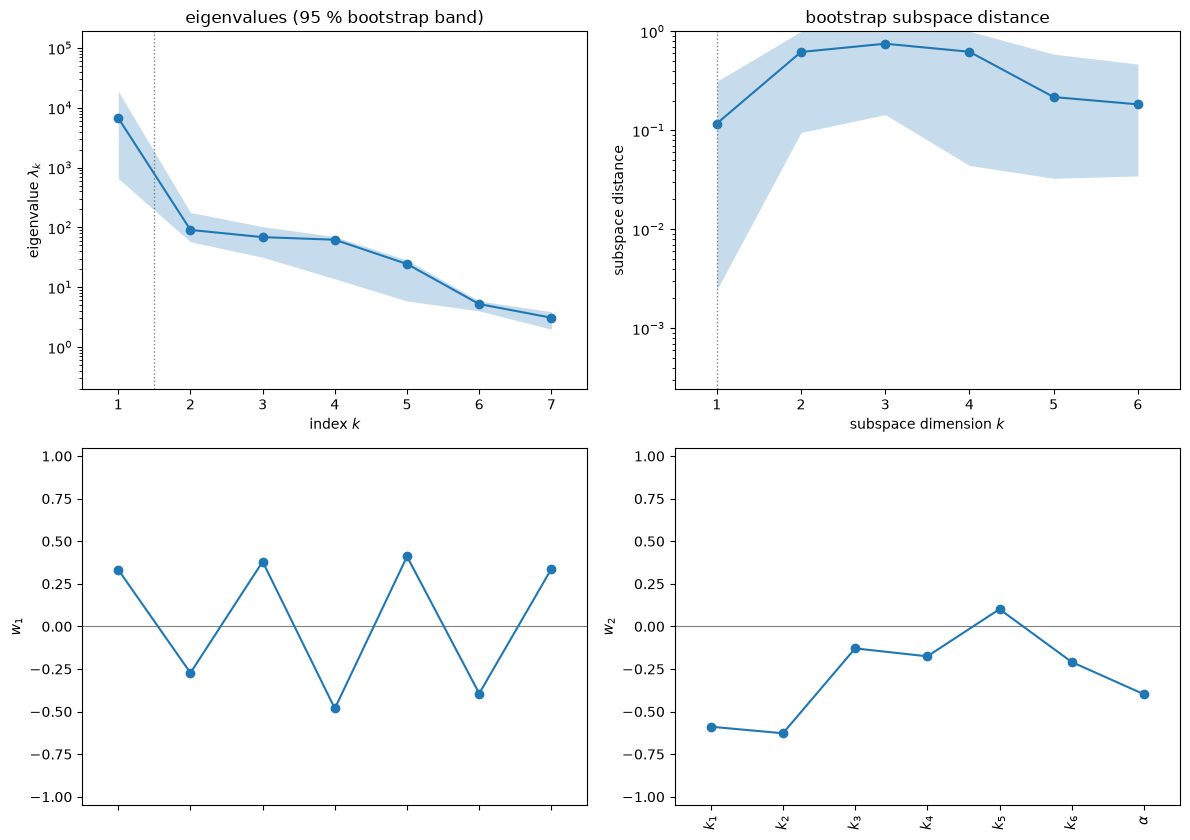

In [11]:
key = '3: log design, x3_high'
fig = four_panels(subs[key])
zn = space_l.to_normalized(Zl)
print('the 5 samples with the largest gradients (normalized log inputs):')
for i in top5[key]:
    print(f'  row {i:3d}: ' + ', '.join(f'{n} {v:+.2f}' for n, v in zip(NAMES, zn[i])) +
          f';  x3 high/low x0 = {Fl[i, 1]:.2f}/{Fl[i, 3]:.2f} nM')
print(f'largest |normalized log input| among them: {np.abs(zn[top5[key]]).max():.3f}')
fig

In log coordinates inside the paper's box the first eigenvalue stands out. The robust value is $\lambda_1/\lambda_2 \approx 12$: 12.80 without row 306, 10.52 without the 5 largest gradients, 11.99 on rows 0–255, with $\mathbf w_1$ stable ($|\mathbf w_1^T\mathbf w_1'| \ge 0.955$; robustness cell above). With all 512 samples the printed ratio is 74.42 (bootstrap 2.5–97.5 %: 10.14 to 210.8), but only because row 306 alone carries 83.7 % of the trace; $\lambda_2/\lambda_3 = 1.32$, and the mean subspace distance for $n = 1$ is 0.117. At that point the two initial conditions end in different states (16.30 and 3.31 nM), and the high-state trajectory is still near the separatrix at 30 min. Without that row the ratio is 12.80. Unlike the large gradients in Study 1, these samples are not at a corner of the box: row 306 has every normalized log input within $\pm 0.87$. $\mathbf w_1 = (0.333, -0.273, 0.380, -0.482, 0.411, -0.394, 0.338)$: $x_3$ rises with the activation rates $k_1, k_3, k_5$ and the feedback strength $\alpha$ and falls with the deactivation rates $k_2, k_4, k_6$, with weights of similar size (0.27 to 0.48 in absolute value).

y1 in [-1.55, 1.65]; corr(y1, f) = 0.8833


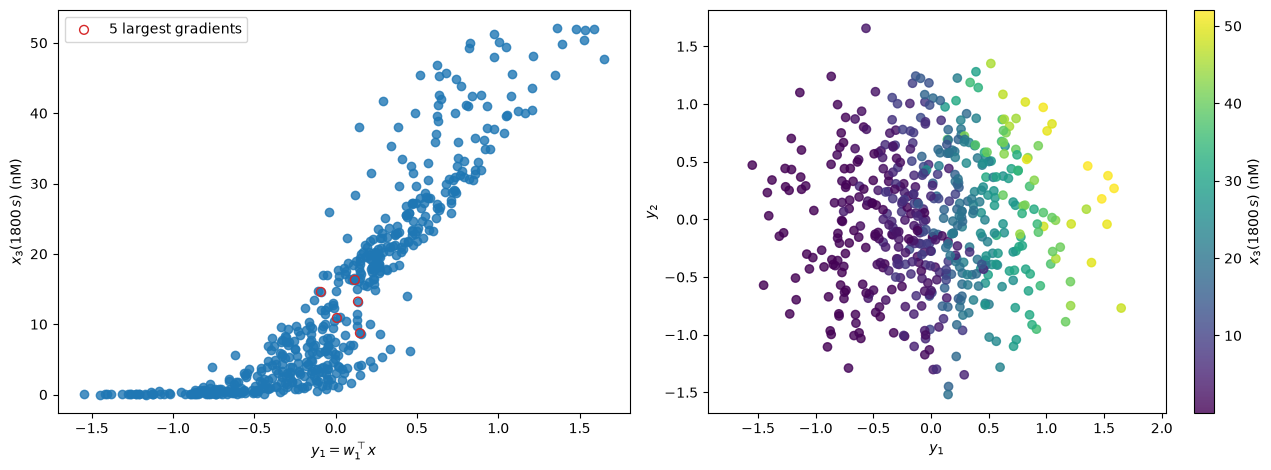

In [12]:
summaries(subs[key], Zl, Fl[:, 1], '$x_3(1800\\,s)$ (nM)', space_l, mark=top5[key], mark_label='5 largest gradients')

The one-dimensional summary plot shows a clear increasing trend, $\mathrm{corr}(y_1, f) = 0.883$. $x_3$ rises from near 0 to about 53 nM, the total $S_{3t}$. Around $y_1 \approx 0$, where whether a sample reaches the high or the low state depends on more than $y_1$, there is a band of scatter (255 of 512 samples are bistable here). The five largest gradients (red circles) sit in that band. In the two-dimensional plot the colour changes mainly along $y_1$.

### Results, Study 1 (secondary): the paper's linear bistable design, $f_B = x_3(1800\,\mathrm{s})$

This and Study 2 use the paper's own ranges, which start at 0. They show how the gradient-based matrix behaves on that design.

lambda_1/lambda_2 = 10.369 (2.5-97.5 % over replicates [1.499, 41.240]); lambda_2/lambda_3 = 1.471
bootstrap mean subspace distance: k = 1: 0.152, k = 2: 0.533, k = 3: 0.318, k = 4: 0.348, k = 5: 0.566, k = 6: 0.555
w1 = [ 0.011 -0.01   0.004 -0.012  0.014 -1.     0.013]
w2 = [ 0.141 -0.614  0.087 -0.605  0.095  0.022  0.469]
the 5 samples with the largest gradients (inputs normalized to [-1, 1]; -1 is the lower bound 0):
  row 252: k1 +0.325, k2 -0.472, k3 -0.360, k4 -0.741, k5 -0.895, k6 -0.997, alpha -0.838;  x3 = 39.80 nM
  row 261: k1 -0.973, k2 +0.718, k3 +0.708, k4 -0.204, k5 +0.587, k6 -0.995, alpha +0.680;  x3 = 36.37 nM
  row  98: k1 -0.631, k2 -0.821, k3 -0.002, k4 -0.360, k5 +0.036, k6 +0.162, alpha -0.851;  x3 = 11.38 nM
  row 113: k1 -0.360, k2 +0.174, k3 +0.534, k4 -0.997, k5 +0.088, k6 -0.037, alpha -0.270;  x3 = 43.19 nM
  row  92: k1 +0.297, k2 -0.373, k3 +0.241, k4 +0.512, k5 +0.913, k6 -0.131, alpha -0.911;  x3 = 16.28 nM


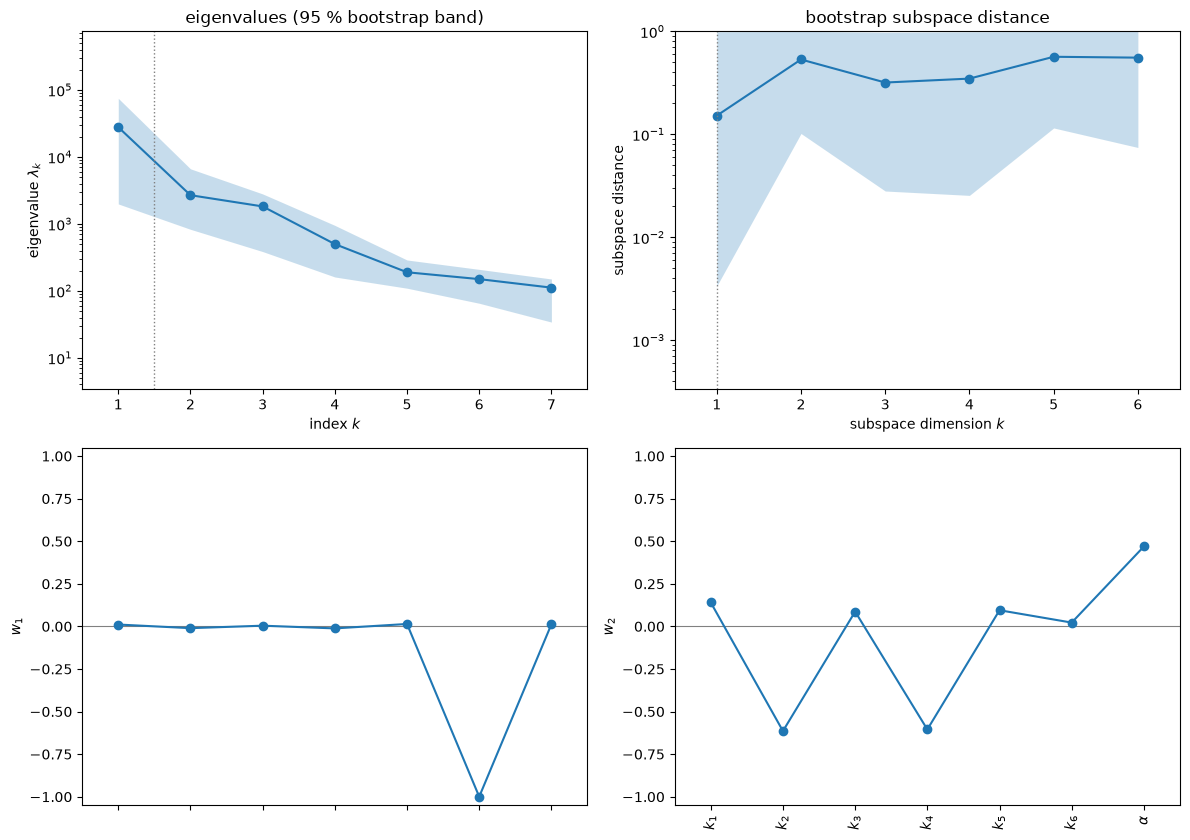

In [13]:
key = '1: bistable, x3_high'
fig = four_panels(subs[key])
xn = space_b.to_normalized(Xb)
print('the 5 samples with the largest gradients (inputs normalized to [-1, 1]; -1 is the lower bound 0):')
for i in top5[key]:
    print(f'  row {i:3d}: ' + ', '.join(f'{n} {v:+.3f}' for n, v in zip(NAMES, xn[i])) + f';  x3 = {Fb[i, 1]:.2f} nM')
fig

$\lambda_1/\lambda_2 = 10.37$, but the bootstrap replicates put it anywhere from 1.50 to 41.24, and $\mathbf w_1$ is the $k_6$ axis ($w_{6,1} = -1.000$). The cause is printed above: two of the five samples with the largest gradients have $k_6$ within 0.3 % of the range above 0 (normalized $-0.997$, $-0.995$), and one has $k_4$ there ($-0.997$). With a deactivation rate near 0, $x_3$ approaches its total, and its derivative with respect to that rate is large (at steady state $x_3 = k_5 S_{3t} x_2/(k_5 x_2 + k_6)$, so $\partial x_3/\partial k_6 = -S_{3t}/(k_5 x_2)$ at $k_6 = 0$). These few corner samples, not the bulk of the design, set $\mathbf w_1$: without the 5 largest gradients $\lambda_1/\lambda_2 = 1.59$ and $\mathbf w_1$ is mostly $k_4$ (robustness cell above). $\mathbf w_2$ is a combination of $k_2$ ($-0.614$), $k_4$ ($-0.605$) and $\alpha$ (0.469).

y1 in [-1.02, 1.01]; corr(y1, f) = 0.3903


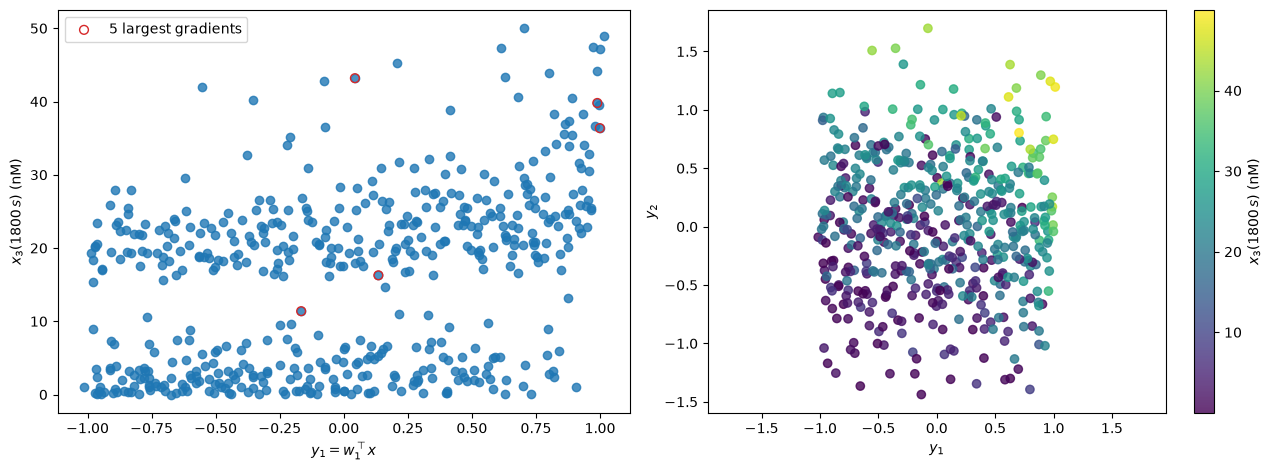

In [14]:
summaries(subs[key], Xb, Fb[:, 1], '$x_3(1800\\,s)$ (nM)', space_b, mark=top5[key], mark_label='5 largest gradients')

Since $\mathbf w_1$ is the $k_6$ axis, $y_1$ is essentially $-k_6$ in normalized units. The one-dimensional summary plot shows two bands, one at 0–10 nM and one at about 15–30 nM, each rising mildly with $y_1$ and most steeply as $y_1 \to 1$ ($k_6 \to 0$); which band a sample is in depends on the other inputs, and $\mathrm{corr}(y_1, f) = 0.39$. On the paper's linear ranges starting at 0, $x_3(30\,\mathrm{min})$ has no useful low-dimensional active subspace in the gradient sense: the direction is set by the corner $k_6 \approx 0$, and the bands are not separated by $y_1$ or $y_2$.

In [15]:
# All four bistable outputs in Study 3 (and x3 in Study 1), for comparison: eigenvalue ratios and w1
for st, sp, Z, F, G in [('log', space_l, Zl, Fl, Gzl), ('paper', space_b, Xb, Fb, Gb)]:
    for k, name in enumerate(['x2_high', 'x3_high', 'x2_low', 'x3_low']):
        if st == 'paper' and k in (0, 2):
            continue
        s = ac.active_subspace(space=sp, X=Z, f=F[:, k], grads=G[:, k], estimator='as', nboot=200, rng=SEED)
        s = ac.orient(s, by='covariance', X=Z, f=F[:, k], columns=7)
        lam, b = s.eigenvalues, s.bootstrap_eigenvalues
        lo, hi = np.percentile(b[:, 0] / b[:, 1], [2.5, 97.5])
        print(f'{st:5s} {name:8s} l1/l2 = {lam[0] / lam[1]:6.2f} [{lo:6.2f}, {hi:6.2f}], l2/l3 = {lam[1] / lam[2]:5.2f}, '
              f'w1 = {np.array2string(s.W[:, 0], precision=2, suppress_small=True)}')

log   x2_high  l1/l2 =   3.65 [  3.08,  10.25], l2/l3 =  4.75, w1 = [ 0.31 -0.4   0.43 -0.54  0.26 -0.25  0.36]


log   x3_high  l1/l2 =  74.42 [ 10.39, 243.08], l2/l3 =  1.32, w1 = [ 0.33 -0.27  0.38 -0.48  0.41 -0.39  0.34]


log   x2_low   l1/l2 =   4.69 [  1.13,  14.31], l2/l3 = 13.57, w1 = [ 0.21 -0.15  0.43 -0.35  0.56 -0.54  0.14]
log   x3_low   l1/l2 =  10.47 [  6.31,  20.39], l2/l3 =  2.71, w1 = [ 0.24 -0.22  0.38 -0.49  0.51 -0.47  0.15]


paper x3_high  l1/l2 =  10.37 [  1.44,  37.57], l2/l3 =  1.47, w1 = [ 0.01 -0.01  0.   -0.01  0.01 -1.    0.01]


paper x3_low   l1/l2 =  12.28 [  1.60,  38.68], l2/l3 =  1.68, w1 = [ 0.01 -0.01  0.   -0.01  0.01 -1.    0.01]


In the log design every bistable output has a dominant first eigenvalue, but the gap depends on the output. $x_3$ from the high-state initial condition has 74.42 with all samples (bootstrap 10.39 to 243.08 with the 200 replicates of this cell; about 12 without row 306, see above), $x_3$ from the low-state one 10.47 (6.31 to 20.39), and $x_2$ 3.65 (3.08 to 10.25) and 4.69 (1.13 to 14.31). All four first eigenvectors have the activation rates $k_1, k_3, k_5$ and $\alpha$ positive and the deactivation rates $k_2, k_4, k_6$ negative. In the paper's design both $x_3$ outputs give the same $k_6$ axis, with bootstrap intervals for $\lambda_1/\lambda_2$ that reach down to 1.44 and 1.60.

### Results, Study 2: the paper's oscillatory design (linear ranges)

#### Limit-cycle amplitude and period on the oscillating samples (Study 2 headline)

**Rule for "oscillating".** A sample oscillates when the paper's Sec. 1.13 rule, with the thresholds of the authors' code, detects a limit cycle of $x_3$ on the 20 s grid over $980 \le t \le 5400$ s. The rule requires local maxima and minima, a spread of the peak heights below 17 nM, a mean amplitude above 1 nM, a spread of the cycle amplitudes below 5 nM, and at least two maxima or two minima (`MAPK_model.limit_cycle_features`). This is the column `oscillates` = 1, and it is equivalent to amplitude > 0.

Where no limit cycle is found, the paper sets the QoIs to 0 (`nullValue`). An analysis over all samples therefore mixes the jump between 0 and at least 1 nM with the trend of the amplitude inside the oscillating region. Here we keep only the oscillating samples. We estimate gradients among them by local linear fits (`ac.local_linear_gradients`, default $p = 11$ nearest oscillating neighbours, the same input space) and use 500 bootstrap replicates. The oscillating region is not a box, so this is the active subspace of the amplitude restricted to that region. The all-sample version follows; it is the like-for-like comparison with the paper's Sobol' indices, which include the 0s.

In [16]:
# Oscillating samples: the Sec. 1.13 rule detects a limit cycle of x3 in 980-5400 s (column 'oscillates' = 1,
# equivalently amplitude > 0: maxima and minima exist, peak-height spread < 17 nM, mean amplitude > 1 nM,
# amplitude spread < 5 nM, at least two maxima or minima)
osc = Fo[:, 3] == 1
print(f'oscillating samples: {osc.sum()} of {len(Fo)}; amplitude > 0 exactly there: {np.array_equal(Fo[:, 1] > 0, osc)}; '
      f'period > 0 there: {np.all(Fo[osc, 2] > 0)}')
xo = space_o.to_normalized(Xo)
Xc, xc = Xo[osc], xo[osc]
cond = {}
for name, col in [('amplitude', 1), ('period', 2)]:
    g = ac.local_linear_gradients(X=Xc, f=Fo[osc, col], space=space_o)
    s = ac.active_subspace(grads=g, estimator='as', nboot=500, rng=SEED)
    cond[name] = ac.orient(s, by='covariance', X=Xc, f=Fo[osc, col], columns=7)
    lam, b = cond[name].eigenvalues, cond[name].bootstrap_eigenvalues
    lo, hi = np.percentile(b[:, 0] / b[:, 1], [2.5, 97.5])
    d = cond[name].bootstrap_distances.mean(axis=0)
    a = ac.activity_scores(cond[name], n=7)
    y1 = xc @ cond[name].W[:, 0]
    print(f'{name} | oscillating: lambda_1/lambda_2 = {lam[0] / lam[1]:.2f} (2.5-97.5 % [{lo:.2f}, {hi:.2f}]), '
          f'lambda_2/lambda_3 = {lam[1] / lam[2]:.2f}; mean subspace distance k = 1: {d[0]:.3f}; '
          f'corr(y1, f) = {np.corrcoef(y1, Fo[osc, col])[0, 1]:.3f}')
    print(f'   w1 = {np.array2string(cond[name].W[:, 0], precision=2, suppress_small=True)}; activity scores ' +
          ', '.join(f'{NAMES[i]} ({a[i] / a.sum():.2f})' for i in np.argsort(-a)))
A = np.c_[np.ones(osc.sum()), xc]
c, *_ = np.linalg.lstsq(A, Fo[osc, 1], rcond=None)
r2 = 1 - np.sum((A @ c - Fo[osc, 1]) ** 2) / np.sum((Fo[osc, 1] - Fo[osc, 1].mean()) ** 2)
print(f'least squares, amplitude on normalized inputs (oscillating samples): R^2 = {r2:.3f}; slopes (nM) ' +
      ', '.join(f'{n} {v:+.1f}' for n, v in zip(NAMES, c[1:])))
g = ac.local_linear_gradients(X=Xo, f=Fo[:, 3], space=space_o)
sF = ac.active_subspace(grads=g, estimator='as', nboot=200, rng=SEED)
sF = ac.orient(sF, by='covariance', X=Xo, f=Fo[:, 3], columns=7)
print(f'the 0/1 flag itself (all 512, local-linear): lambda_1/lambda_2 = {sF.eigenvalues[0] / sF.eigenvalues[1]:.2f}, '
      f'w1 = {np.array2string(sF.W[:, 0], precision=2, suppress_small=True)}')

oscillating samples: 171 of 512; amplitude > 0 exactly there: True; period > 0 there: True


amplitude | oscillating: lambda_1/lambda_2 = 5.67 (2.5-97.5 % [3.38, 9.40]), lambda_2/lambda_3 = 1.65; mean subspace distance k = 1: 0.093; corr(y1, f) = 0.866
   w1 = [ 0.13 -0.85  0.1   0.23  0.11  0.24  0.36]; activity scores k2 (0.51), alpha (0.17), k4 (0.09), k6 (0.08), k5 (0.06), k3 (0.05), k1 (0.05)


period | oscillating: lambda_1/lambda_2 = 5.34 (2.5-97.5 % [3.36, 6.69]), lambda_2/lambda_3 = 1.21; mean subspace distance k = 1: 0.090; corr(y1, f) = 0.761
   w1 = [-0.01 -0.98  0.03 -0.11 -0.03 -0.15  0.05]; activity scores k2 (0.58), k4 (0.10), alpha (0.08), k5 (0.07), k6 (0.07), k1 (0.06), k3 (0.04)
least squares, amplitude on normalized inputs (oscillating samples): R^2 = 0.780; slopes (nM) k1 +1.8, k2 -44.5, k3 +4.6, k4 +14.5, k5 +7.5, k6 +12.4, alpha +25.1


the 0/1 flag itself (all 512, local-linear): lambda_1/lambda_2 = 1.34, w1 = [ 0.02 -0.55 -0.02  0.82  0.07  0.15 -0.06]


On the 171 oscillating samples the amplitude has $\lambda_1/\lambda_2 = 5.67$ (bootstrap 3.38 to 9.40), with mean subspace distance 0.093 for $n = 1$ and $\mathrm{corr}(y_1, f) = 0.866$. $\mathbf w_1 = (0.13, -0.85, 0.10, 0.23, 0.11, 0.24, 0.36)$ is led by $k_2$: the amplitude falls with $k_2$ and rises with $\alpha$. The activity score of $k_2$ is 0.51, followed by $\alpha$ at 0.17. A linear fit in the normalized inputs has $R^2 = 0.780$, and its largest slope is that of $k_2$ ($-44.5$ nM). The period has $\lambda_1/\lambda_2 = 5.34$ (3.36 to 6.69), and its $\mathbf w_1$ is nearly the $k_2$ axis ($-0.98$; activity score 0.58). The 0/1 flag itself has $\lambda_1/\lambda_2 = 1.34$, with $\mathbf w_1$ led by $k_4$ (0.82) and $k_2$ ($-0.55$), so whether the model oscillates has no one-dimensional structure. This conditional analysis agrees with Fig. 4D of the paper, where $k_2$ has by far the largest first-order Sobol' index for both the amplitude and the period.

lambda_1/lambda_2 = 5.671 (2.5-97.5 % over replicates [3.383, 9.402]); lambda_2/lambda_3 = 1.651
bootstrap mean subspace distance: k = 1: 0.093, k = 2: 0.378, k = 3: 0.439, k = 4: 0.685, k = 5: 0.581, k = 6: 0.704
w1 = [ 0.128 -0.851  0.1    0.227  0.108  0.237  0.361]
w2 = [-0.151  0.425  0.125  0.141  0.303  0.037  0.817]


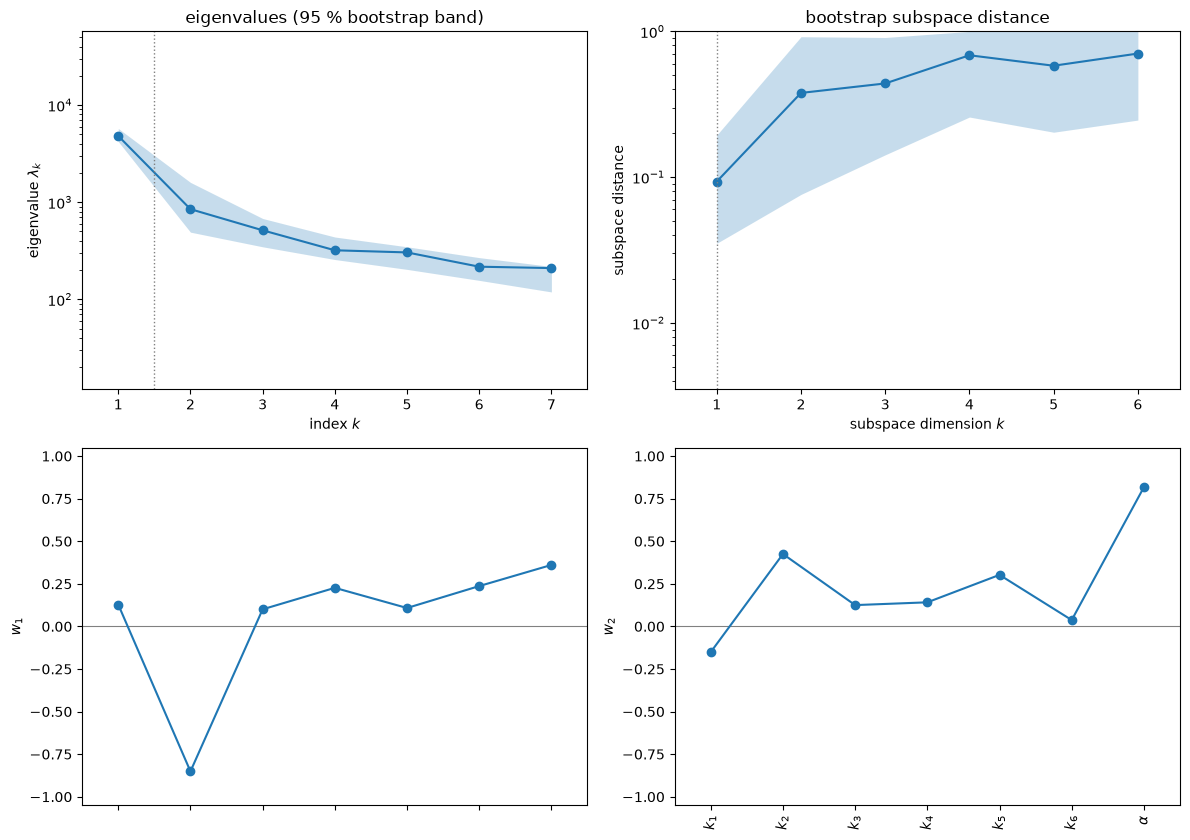

In [17]:
fig = four_panels(cond['amplitude'])
fig

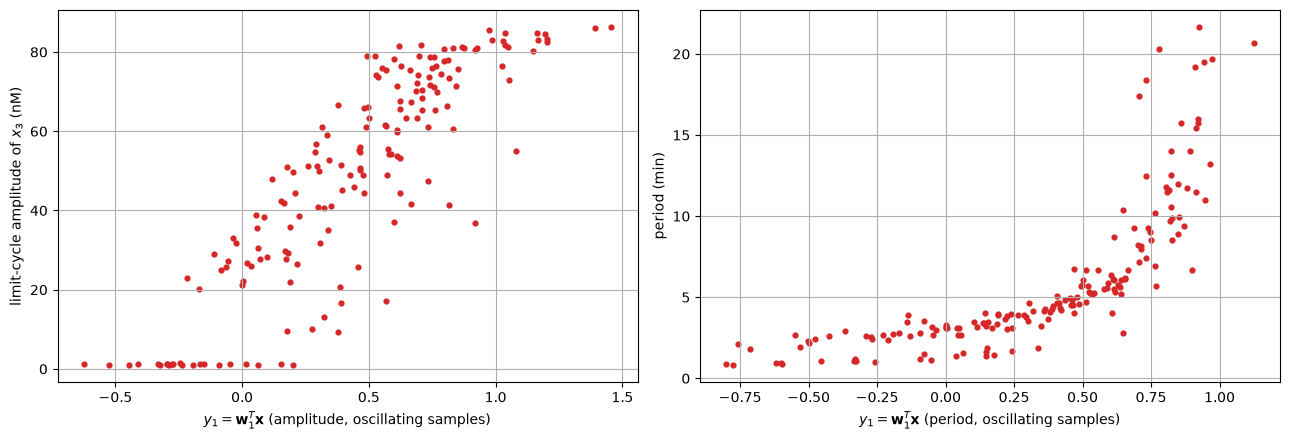

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (name, col, ylab) in zip(axes, [('amplitude', 1, 'limit-cycle amplitude of $x_3$ (nM)'), ('period', 2, 'period (min)')]):
    ax.scatter(xc @ cond[name].W[:, 0], Fo[osc, col], s=12, c='C3')
    ax.set_xlabel(r'$y_1 = \mathbf{w}_1^T \mathbf{x}$ (' + name + ', oscillating samples)')
    ax.set_ylabel(ylab)
    ax.grid(True)
fig.tight_layout()
plt.close(fig)
fig

The amplitude rises along its $y_1$ from about 1 nM, the small cycles near the edge of the oscillating region, to about 85 nM, where it levels off; the scatter is widest in the middle. The period rises along its own $y_1$, which is essentially $-k_2$, from about 1 min to about 20 min, steeply for the largest $y_1$, i.e. the smallest $k_2$.

#### Amplitude on all samples, 0 where no limit cycle (secondary; like-for-like with the paper's Sobol' indices)

The amplitude is 0 where no limit cycle is detected and jumps to more than 1 nM (the detection threshold) where one is, so its gradient does not exist on the edge of the oscillating region; peak detection on a 20 s grid adds small jumps inside it. As above, we estimate gradients from the values alone by local linear fits on the nearest neighbours of each sample, now over all 512 samples. Near the edge of the oscillating region these slopes measure the jump across it, so the result mixes the switch between oscillating and not with the trend of the amplitude. The paper's Sobol' indices are computed the same way, with the 0s (`nullValue = 0`).

eigenvalues (local-linear gradients) [2923.693  1417.5463 1202.2122 1066.7722  870.7209  779.9726  660.9032]
lambda_1/lambda_2 = 2.063, lambda_2/lambda_3 = 1.179; w1 = [ 0.146 -0.747  0.148  0.448  0.029  0.37   0.246]
bootstrap mean subspace distance k = 1: 0.170, k = 2: 0.486


fraction with a limit cycle by quarter of the k2 range: 0.63, 0.43, 0.22, 0.05
amplitude over the limit-cycle samples: 1.01 to 86.34 nM; corr(y1, amplitude) over all samples 0.635
149 samples have amplitude > 5 nM, all at y1 >= -0.18; 155 samples without a limit cycle are there too


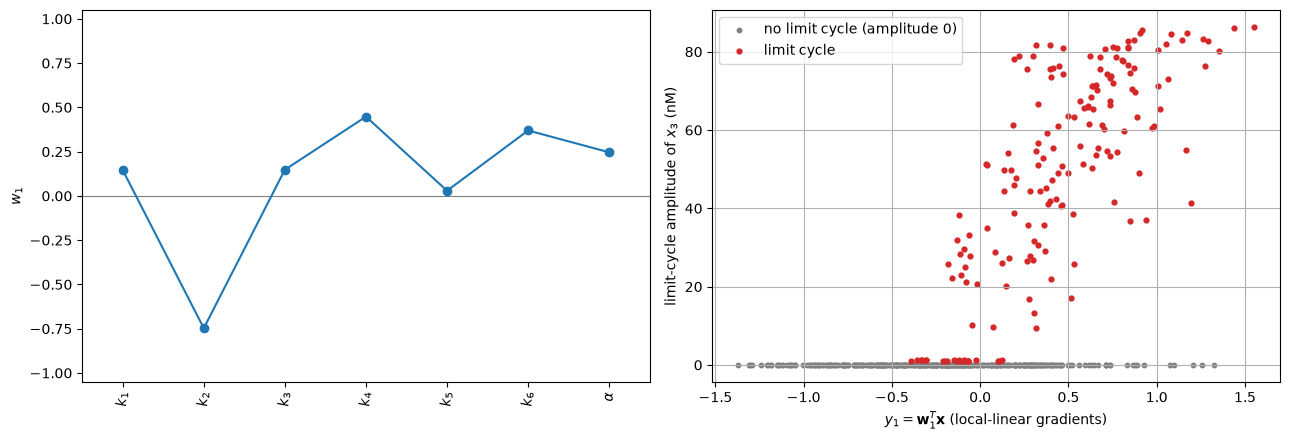

In [19]:
fA = Fo[:, 1]                     # all 512 samples, 0 where no limit cycle (the paper's nullValue = 0)
gA = ac.local_linear_gradients(X=Xo, f=fA, space=space_o)
sA = ac.active_subspace(grads=gA, estimator='as', nboot=500, rng=SEED)
sA = ac.orient(sA, by='covariance', X=Xo, f=fA, columns=7)
lamA = sA.eigenvalues
print('eigenvalues (local-linear gradients) ' + np.array2string(lamA, precision=4))
print(f'lambda_1/lambda_2 = {lamA[0] / lamA[1]:.3f}, lambda_2/lambda_3 = {lamA[1] / lamA[2]:.3f}; w1 = {np.array2string(sA.W[:, 0], precision=3)}')
d = sA.bootstrap_distances.mean(axis=0)
print(f'bootstrap mean subspace distance k = 1: {d[0]:.3f}, k = 2: {d[1]:.3f}')
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ac.plotting.plot_eigenvectors(sA, indices=[0], labels=labels, ax=[axes[0]])
yA = xo @ sA.W[:, 0]
axes[1].scatter(yA[~osc], fA[~osc], s=10, c='0.5', label='no limit cycle (amplitude 0)')
axes[1].scatter(yA[osc], fA[osc], s=12, c='C3', label='limit cycle')
axes[1].set_xlabel(r'$y_1 = \mathbf{w}_1^T \mathbf{x}$ (local-linear gradients)')
axes[1].set_ylabel('limit-cycle amplitude of $x_3$ (nM)')
axes[1].legend(); axes[1].grid(True)
fig.tight_layout()
plt.close(fig)
print('fraction with a limit cycle by quarter of the k2 range: ' +
      ', '.join(f'{np.mean(osc[(xo[:, 1] >= a) & (xo[:, 1] < b)]):.2f}' for a, b in [(-1, -.5), (-.5, 0), (0, .5), (.5, 1.01)]))
print(f'amplitude over the limit-cycle samples: {fA[osc].min():.2f} to {fA[osc].max():.2f} nM; '
      f'corr(y1, amplitude) over all samples {np.corrcoef(yA, fA)[0, 1]:.3f}')
big = osc & (fA > 5)
print(f'{big.sum()} samples have amplitude > 5 nM, all at y1 >= {yA[big].min():.2f}; '
      f'{np.sum(~osc & (yA >= yA[big].min()))} samples without a limit cycle are there too')
fig

Over all samples the local-linear estimate gives $\lambda_1/\lambda_2 = 2.06$ and $\lambda_2/\lambda_3 = 1.18$, so there is no strong one-dimensional structure. $\mathbf w_1$ is stable (mean subspace distance 0.170) and is led by $k_2$ ($-0.747$), then $k_4$ (0.448) and $k_6$ (0.370); $k_2$'s activity score is only 0.24, against 0.51 on the oscillating samples. The amplitude correlates with $y_1$ at 0.635. Every limit cycle with an amplitude above 5 nM (149 samples) lies at $y_1 \ge -0.18$, and there the amplitude rises with $y_1$ up to 86.34 nM. But 155 samples without a limit cycle share that range, so $y_1$ does not decide whether the model oscillates. The share of samples with a limit cycle falls from 0.63 in the lowest quarter of the $k_2$ range to 0.05 in the highest.

#### The window-mean of $x_3$ (not a paper QoI; a negative result)

$f_O = \overline{x_3}$ over $980 \le t \le 5400$ s is smooth and has exact gradients. The authors' script computes it, but the paper does not show it. In oscillating samples its gradient is dominated by phase drift: how many periods fit in the window changes with the parameters that set the period.

lambda_1/lambda_2 = 2.211 (2.5-97.5 % over replicates [1.080, 8.418]); lambda_2/lambda_3 = 1.522
bootstrap mean subspace distance: k = 1: 0.352, k = 2: 0.447, k = 3: 0.045, k = 4: 0.242, k = 5: 0.351, k = 6: 0.402
w1 = [ 0.     0.015 -0.     0.007 -0.008  1.    -0.   ]
w2 = [-0.    -0.025 -0.    -0.999  0.02   0.007  0.001]
the 5 samples with the largest gradients (inputs normalized to [-1, 1]):
  row 414: k1 +0.652, k2 +0.991, k3 +0.914, k4 +0.410, k5 +0.626, k6 -0.997, alpha +0.415;  mean x3 = 64.69 nM, limit cycle: no
  row 103: k1 -0.050, k2 -0.865, k3 -0.217, k4 +0.518, k5 -0.270, k6 -0.994, alpha -0.352;  mean x3 = 63.44 nM, limit cycle: no
  row 160: k1 -0.300, k2 +0.585, k3 +0.112, k4 -0.994, k5 -0.873, k6 +0.027, alpha +0.864;  mean x3 = 68.83 nM, limit cycle: no
  row 461: k1 +0.222, k2 -0.333, k3 +0.224, k4 -0.986, k5 -0.523, k6 +0.953, alpha -0.523;  mean x3 = 58.69 nM, limit cycle: no
  row 196: k1 -0.726, k2 +0.434, k3 -0.434, k4 +0.385, k5 +0.105, k6 -0.990, alpha +0.831

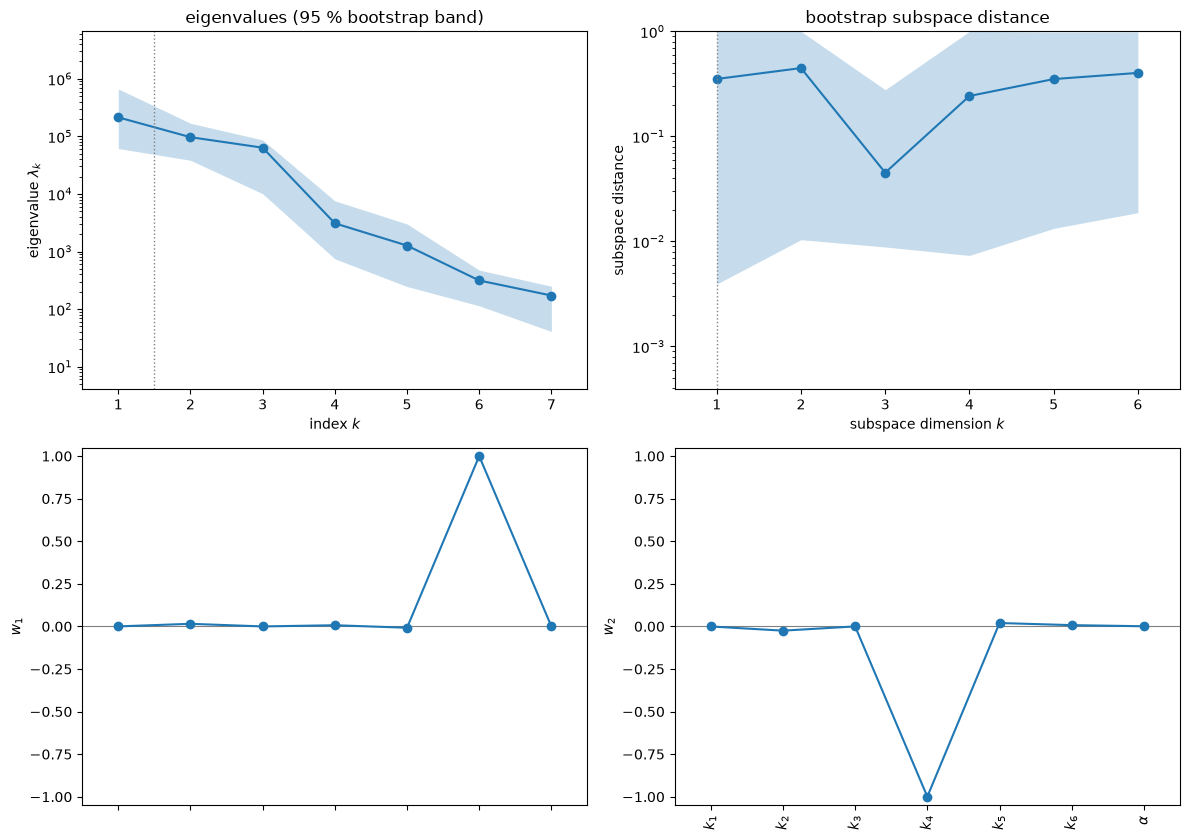

In [20]:
key = '2: oscillatory, mean_x3'
fig = four_panels(subs[key])
xo = space_o.to_normalized(Xo)
print('the 5 samples with the largest gradients (inputs normalized to [-1, 1]):')
for i in top5[key]:
    print(f'  row {i:3d}: ' + ', '.join(f'{n} {v:+.3f}' for n, v in zip(NAMES, xo[i])) +
          f';  mean x3 = {Fo[i, 0]:.2f} nM, limit cycle: {"yes" if osc[i] else "no"}')
fig

For the mean of $x_3$ in the oscillatory design, $\lambda_1/\lambda_2 = 2.21$ (bootstrap 1.08 to 8.42); $\mathbf w_1$ is the $k_6$ axis and $\mathbf w_2$ the $k_4$ axis. The five largest gradients come from samples without a limit cycle and with $k_6$ or $k_4$ in the lowest 0.7 % of its range (normalized $\le -0.986$), the same corner effect as in Study 1. Without them $\lambda_1/\lambda_2 = 1.20$ and $\mathbf w_1$ is the $k_2$ axis. The third and fourth eigenvalues are separated by a factor of 20.57, so the first three directions (essentially $k_6$, $k_4$ and $k_2$) carry almost all of $\hat{\mathbf C}$. They come from the corners and from the period, not from a shared trend.

y1 in [-1.00, 1.01]; corr(y1, f) = 0.0792


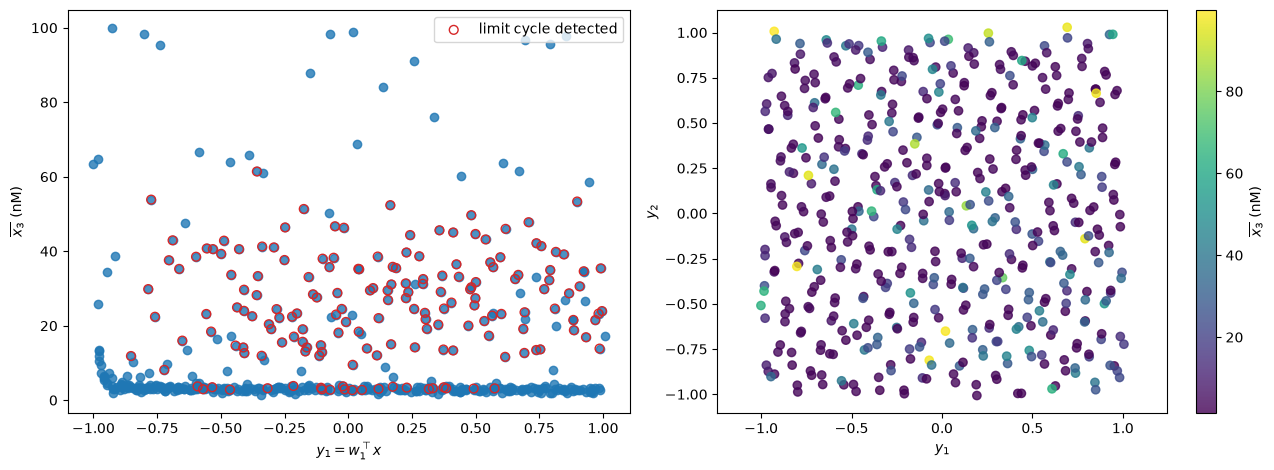

In [21]:
summaries(subs[key], Xo, Fo[:, 0], r'$\overline{x_3}$ (nM)', space_o, mark=osc, mark_label='limit cycle detected')

The summary plot has $\mathrm{corr}(y_1, f) = 0.079$: the mean of $x_3$ does not follow $y_1$. Most samples without a limit cycle sit near 3 nM, a few (near $k_4$ or $k_6 = 0$) reach 60–100 nM, and the samples with a limit cycle (red circles) spread between about 5 and 55 nM at every $y_1$. Gradient-based dimension reduction is not informative for this QoI on these ranges: the direction is set by the corners, and the separation between oscillating and non-oscillating samples, which carries most of the variance, does not lie along $y_1$ or $y_2$.

#### Surrogates on the active variables

Polynomials in the first one or two active variables, with leave-one-out $R^2$.

1: bistable, x3_high     cubic, n = 1  LOO R^2 = 0.1835
1: bistable, x3_high     cubic, n = 2  LOO R^2 = 0.5296
3: log design, x3_high   cubic, n = 1  LOO R^2 = 0.8669
3: log design, x3_high   cubic, n = 2  LOO R^2 = 0.9083
2: oscillatory, mean_x3  cubic, n = 1  LOO R^2 = -0.0076
2: oscillatory, mean_x3  cubic, n = 2  LOO R^2 = 0.0214


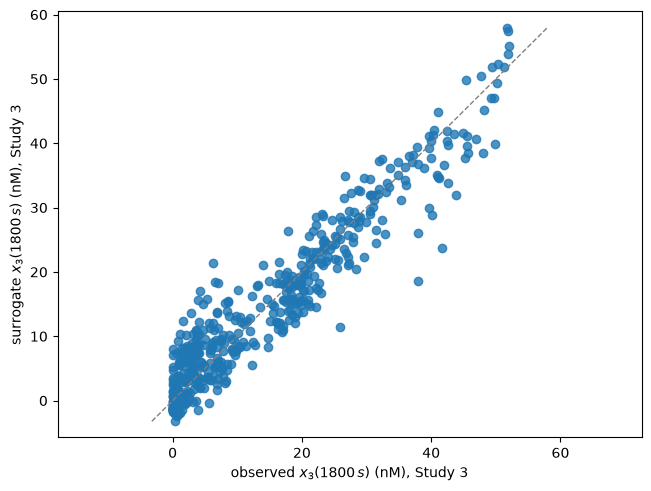

In [22]:
loo = {}
for key, (sp, X, f, g) in cases.items():
    for name, n, deg in [('cubic, n = 1', 1, 3), ('cubic, n = 2', 2, 3)]:
        s = ac.fit_surrogate(X=X, f=f, space=sp, subspace=ac.with_dimension(subs[key], n), kind='poly', degree=deg)
        loo[key, n] = s.loo_r_squared
        print(f'{key:24s} {name:13s} LOO R^2 = {s.loo_r_squared:.4f}')
key = '3: log design, x3_high'
s = ac.fit_surrogate(X=Zl, f=Fl[:, 1], space=space_l, subspace=ac.with_dimension(subs[key], 2), kind='poly', degree=3)
fig, ax = ac.plotting.plot_surrogate_fit(s, X=Zl, f=Fl[:, 1], qoi_label='$x_3(1800\\,s)$ (nM), Study 3')
plt.close(fig)
fig

For $x_3$ in the log design (Study 3), a cubic in one active variable has leave-one-out $R^2 = 0.867$, and a cubic in two has 0.908; the plot shows the two-variable fit. On the paper's bistable design the same surrogates give 0.184 and 0.530, and for the oscillatory mean $-0.008$ and 0.021, so no surrogate on these active variables is useful there.

### Comparison with the paper

The paper [[1]][R1] does not compute an active subspace. It reports Sobol' first- and total-order indices from UQLab with a Sobol' sequence (Fig. 4C–D, p. 27, bar charts without printed values) and selects the parameters to estimate from them. We compare its rankings with the normalized activity scores $\alpha_i/\sum_j \alpha_j$, $\alpha_i = \sum_{k=1}^{7} \lambda_k w_{ik}^2$, which equal the normalized mean squared partial derivatives $\mathbb E[(\partial f/\partial x_i)^2]$, a derivative-based sensitivity measure; for the amplitude and the period we use the same scores from the local-linear gradients, on the oscillating samples and (amplitude) on all samples. For the gradient-based studies we also print the scores without the 5 largest gradients. The paper's rankings are read from the order of the bars.

In [23]:
def ranking(v):
    o = np.argsort(-v)
    return ', '.join(f'{NAMES[i]} ({v[i]:.2f})' for i in o)
for key, sub in subs.items():
    a = ac.activity_scores(sub, n=7)
    print(f'{key:30s}: {ranking(a / a.sum())}')
    print(f"{'   without the 5 largest':30s}: {ranking(drop[key, 5])}")
s = ac.active_subspace(space=space_b, X=Xb, f=Fb[:, 3], grads=Gb[:, 3], estimator='as')
a = ac.activity_scores(s, n=7)
print(f"{'1: bistable, x3_low':30s}: {ranking(a / a.sum())}")
for name in cond:
    a = ac.activity_scores(cond[name], n=7)
    print(f"{'2: ' + name + ' | oscillating':30s}: {ranking(a / a.sum())}")
a = ac.activity_scores(sA, n=7)
print(f"{'2: amplitude, all (0s incl.)':30s}: {ranking(a / a.sum())}")
print(f"\nStudy 2 limit-cycle samples: {osc.sum()}; amplitude median {np.median(fA[osc]):.2f} nM, period median {np.median(Fo[osc, 2]):.2f} min")

1: bistable, x3_high          : k6 (0.84), k4 (0.06), k2 (0.05), alpha (0.03), k1 (0.01), k5 (0.01), k3 (0.00)
   without the 5 largest      : k4 (0.38), k6 (0.26), k2 (0.20), k5 (0.06), k1 (0.05), k3 (0.04), alpha (0.02)
3: log design, x3_high        : k4 (0.23), k5 (0.17), k6 (0.15), k3 (0.14), alpha (0.12), k1 (0.11), k2 (0.08)
   without the 5 largest      : k4 (0.25), k6 (0.21), k2 (0.20), k5 (0.16), k3 (0.09), alpha (0.05), k1 (0.04)
2: oscillatory, mean_x3       : k6 (0.56), k4 (0.26), k2 (0.17), k5 (0.01), k3 (0.00), alpha (0.00), k1 (0.00)
   without the 5 largest      : k2 (0.49), k4 (0.41), k6 (0.06), k5 (0.02), k3 (0.01), alpha (0.00), k1 (0.00)
1: bistable, x3_low           : k6 (0.86), k4 (0.06), k2 (0.04), alpha (0.02), k1 (0.01), k5 (0.01), k3 (0.01)
2: amplitude | oscillating    : k2 (0.51), alpha (0.17), k4 (0.09), k6 (0.08), k5 (0.06), k3 (0.05), k1 (0.05)
2: period | oscillating       : k2 (0.58), k4 (0.10), alpha (0.08), k5 (0.07), k6 (0.07), k1 (0.06), k3 (0.04)
2

| quantity | paper | this notebook |
|---|---|---|
| free parameters in the sensitivity study | 7 (Fig. 4 caption, code); "9" in the text, p. 28 | 7: $k_1,\dots,k_6,\alpha$ |
| design | Sobol' sequence (UQLab), 5,000 (bistable) and 15,000 (oscillatory) samples, linear ranges from 0 | scrambled Sobol', 512 per design: the paper's two linear designs (Studies 1, 2) and a log-uniform design on $[U/100, U]$ inside the paper's box (Study 3, ours) |
| nominal $x_3$, high and low steady state (nM) | about 18 and 6 (Fig. 4B, read from the plot) | 17.92 and 5.99 at 30 min |
| nominal limit-cycle amplitude (nM) | 26.12, "true value" (p. 30) | 26.06 (settled cycle, authors' late minima); 26.33 (settled cycle, true minima); 26.96 (data window from 980 s, true minima) |
| nominal period (min) | 13.04 (p. 30) | 13.04 (data window); 12.99 (settled cycle) |
| bistable $x_3$: top parameters | high $x_3$, first order: $k_6, k_5, k_4, k_3, k_1, k_2, \alpha$; total: $k_6, k_5, k_3, k_4, k_1, k_2, \alpha$ (Fig. 4C) | Study 3: $k_4$ (0.23), $k_5$ (0.17), $k_6$ (0.15), $k_3$ (0.14), …; without the 5 largest gradients $k_4$ (0.25), $k_6$ (0.21), $k_2$ (0.20), $k_5$ (0.16), … Study 1: $k_6$ (0.84), $k_4$ (0.06), $k_2$ (0.05), …; without the 5 largest $k_4$ (0.38), $k_6$ (0.26), $k_2$ (0.20), … |
| parameters selected for the bistable case | $k_2, k_4, k_5, k_6$ (p. 28) | not a selection; Study 3 without the 5 largest gradients ranks the same four first |
| amplitude: top parameters | $k_2$, then $k_6, k_4, \alpha$ (Fig. 4D) | oscillating samples: $k_2$ (0.51), $\alpha$ (0.17), $k_4$ (0.09), $k_6$ (0.08), …; all samples with the 0s: $k_2$ (0.24), $k_4$ (0.18), $k_6$ (0.17), $\alpha$ (0.12), … |
| period: top parameters | $k_2$, then $k_4, k_6$ (Fig. 4D) | oscillating samples: $k_2$ (0.58), $k_4$ (0.10), $\alpha$ (0.08), … |
| parameters selected for the oscillatory case | $k_2, k_4, k_6, \alpha$ (p. 28) | the same four lead the all-sample amplitude scores; $k_2$ dominates on the oscillating samples |
| share of oscillatory samples with a limit cycle | not reported | 171 of 512 (33.4 %) |
| active subspace | not computed | Study 3 $x_3$: one-dimensional, $\lambda_1/\lambda_2 \approx 12$ (12.8 without row 306, 10.5 without the 5 largest, 12.0 on rows 0–255; 74.4 with all samples, from one near-separatrix sample); amplitude on the oscillating samples: 5.67 |

The paper ranks parameters by variance (Sobol' indices); activity scores rank them by mean squared derivative, which weights steep regions heavily, so the two need not agree.

* *Amplitude and period.* They agree: $k_2$ comes first, clearly so on the oscillating samples (0.51 for the amplitude, 0.58 for the period), and the four parameters the paper selects ($k_2, k_4, k_6, \alpha$) are first in the all-sample amplitude scores.
* *Bistable $x_3$ on the paper's ranges* (Study 1). Our scores put 84 % on $k_6$, from the few samples with $k_6$ near 0. Without the 5 largest gradients they spread over $k_4, k_6, k_2$, closer to the paper's first-order bars, which are spread across $k_6, k_5, k_4, k_3$. The paper's selection keeps $k_2, k_4, k_5, k_6$.
* *Bistable $x_3$ in the log design* (Study 3). Without the 5 largest gradients, the same four selected parameters lead.
* *Fig. 4C labels.* The authors' sensitivity script labels the paper's high-state initial condition as `x0Low` and vice versa (the run scripts and the Fig. 4 caption use the labels as here), so the "low" and "high" panels of Fig. 4C may be swapped. In our data the two $x_3$ outputs give nearly the same scores in Study 1, so this does not change the comparison.

### References

<a name="R1"></a>[1] N. J. Linden, B. Kramer and P. Rangamani, "Bayesian parameter estimation for dynamical models in systems biology", *PLOS Computational Biology* 18(10): e1010651, 2022. [doi:10.1371/journal.pcbi.1010651](https://doi.org/10.1371/journal.pcbi.1010651). Code: [github.com/RangamaniLabUCSD/CIUKF-MCMC](https://github.com/RangamaniLabUCSD/CIUKF-MCMC).

<a name="R2"></a>[2] L. K. Nguyen, A. Degasperi, P. Cotter and B. N. Kholodenko, "DYVIPAC: an integrated analysis and visualisation framework to probe multi-dimensional biological networks", *Scientific Reports* 5: 12569, 2015. [doi:10.1038/srep12569](https://doi.org/10.1038/srep12569).

<a name="R3"></a>[3] P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM, Philadelphia, 2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).

<a name="R4"></a>[4] I. M. Sobol', "Global sensitivity indices for nonlinear mathematical models and their Monte Carlo estimates", *Mathematics and Computers in Simulation* 55(1–3): 271–280, 2001. [doi:10.1016/S0378-4754(00)00270-6](https://doi.org/10.1016/S0378-4754(00)00270-6).

[R1]: #R1
[R2]: #R2
[R3]: #R3
[R4]: #R4

### Acknowledgments

The paper acknowledges support to N. J. Linden from the National Institute of Biomedical Imaging and Bioengineering of the National Institutes of Health (award T32EB9380) and a UCSD Sloan Scholar Fellowship from the Alfred P. Sloan Foundation, and to P. Rangamani from the Air Force Office of Scientific Research MURI grant FA9550-18-1-0051.

In [24]:
print(f'notebook run time {time.perf_counter() - t_start:.0f} s')

notebook run time 335 s
